# Pool funnel by group

Where each analog leaves the pool, by route, approval era and therapeutic area.

Reads the committed tables in `data/processed/` (no rebuild needed) and applies the same rules, in the same order, as the funnel in `checks.md` (`pipeline/checks.py`). Each funnel column is the number of analogs left after that rule.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# run from the repo root or from eda/
ROOT = Path.cwd() if (Path.cwd() / "pipeline").exists() else Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"
pd.set_option("display.max_rows", 100)

## Load and apply the rules

In [2]:
f = pd.read_csv(PROCESSED / "analog_features.csv")
a = pd.read_csv(PROCESSED / "analogs.csv")[["analog_id", "approval date", "Rx"]]
f = f.merge(a, on="analog_id", validate="1:1")

f["year"] = f["approval date"].str[:4].astype(int)
f["era"] = pd.cut(f.year, [2009, 2013, 2017, 2021, 2025], labels=["2010-13", "2014-17", "2018-21", "2022-25"])
# same area definition as launch_eda and volume_vs_shape: ATC level 1, with L split into
# oncology (L01, L02) and immunology (L03, L04)
ATC1 = {"A": "Alimentary & metabolism", "B": "Blood", "C": "Cardiovascular", "D": "Dermatology",
        "G": "GU & sex hormones", "H": "Systemic hormones", "J": "Anti-infectives", "M": "Musculoskeletal",
        "N": "Nervous system", "P": "Antiparasitic", "R": "Respiratory", "S": "Sensory organs", "V": "Various"}
broad = f.class_broad.fillna("")
f["area"] = f.therapeutic_area.str[:1].map(ATC1).fillna("No ATC class")
f.loc[broad.str.startswith(("L01", "L02")), "area"] = "Oncology"
f.loc[broad.str.startswith(("L03", "L04")), "area"] = "Immunology"

# rules in checks.py order
STEPS = {
    "All analogs": pd.Series(True, index=f.index),
    "Has Medicaid data": f.launch_quarter.notna(),
    "Not late launch": ~f.late_launch.fillna(False).astype(bool),
    "No generic in Q0-Q12": ~f.generic_entry_in_window.astype(bool),
    "Enough data": f.enough_data.astype(bool),
}
keep = pd.Series(True, index=f.index)
for name, rule in STEPS.items():
    keep &= rule
    f[name] = keep

# where each analog ends up
f["outcome"] = "no SDUD / late / generic"
f.loc[f["No generic in Q0-Q12"] & (f.quarters_of_data < 12), "outcome"] = "< 12 quarters"
f.loc[f["No generic in Q0-Q12"] & (f.quarters_of_data >= 12) & ~f["Enough data"], "outcome"] = "blank quarter after Q2"
f.loc[f["Enough data"], "outcome"] = "usable"
print(f"{len(f)} analogs, {f['Enough data'].sum()} usable")

426 analogs, 250 usable


In [3]:
def funnel(by):
    t = f.groupby(by, observed=True)[list(STEPS)].sum()
    t["% usable"] = (100 * t["Enough data"] / t["All analogs"]).round(0).astype(int)
    return t

## By route

In [4]:
funnel("route_group")

,All analogs,Has Medicaid data,Not late launch,No generic in Q0-Q12,Enough data,% usable
route_group,,,,,,
oral,332,318,307,307,202,61
sc,94,88,80,80,48,51


## By approval era

Recent approvals haven't had time to build 12 quarters: the usable pool is in practice 2010–2021 approvals.

In [5]:
funnel("era")

,All analogs,Has Medicaid data,Not late launch,No generic in Q0-Q12,Enough data,% usable
era,,,,,,
2010-13,74,74,67,67,59,80
2014-17,98,96,92,92,83,85
2018-21,134,127,122,122,98,73
2022-25,120,109,106,106,10,8


## By therapeutic area

ATC level 1, with L split into oncology (L01, L02) and immunology (L03, L04), as in `launch_eda`.

In [6]:
funnel("area").sort_values("% usable", ascending=False)

,All analogs,Has Medicaid data,Not late launch,No generic in Q0-Q12,Enough data,% usable
area,,,,,,
Sensory organs,1,1,1,1,1,100
Respiratory,10,10,10,10,8,80
Nervous system,52,52,50,50,41,79
Cardiovascular,19,18,18,18,13,68
Alimentary & metabolism,51,46,44,44,34,67
Various,3,3,3,3,2,67
Musculoskeletal,8,8,8,8,5,62
Oncology,104,103,103,103,62,60
Blood,26,26,24,24,15,58


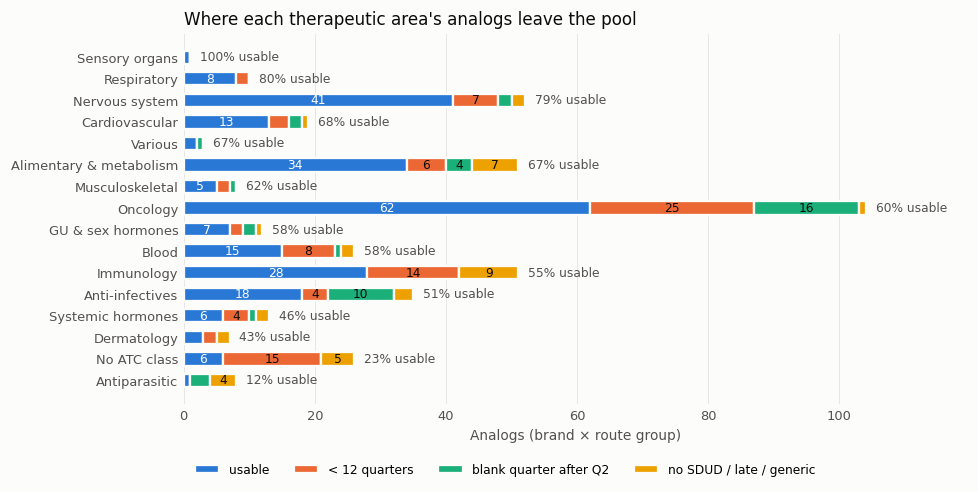

In [7]:
OUTCOMES = ["usable", "< 12 quarters", "blank quarter after Q2", "no SDUD / late / generic"]
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # categorical slots 1-4, validated for colorblind separation
SURFACE, INK, INK2 = "#fcfcfb", "#0b0b0b", "#52514e"

t = pd.crosstab(f.area, f.outcome).reindex(columns=OUTCOMES, fill_value=0)
t = t.loc[(t.usable / t.sum(axis=1)).sort_values().index]

fig, ax = plt.subplots(figsize=(9, 4.6), dpi=110)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)
left = pd.Series(0, index=t.index)
for outcome, color in zip(OUTCOMES, COLORS):
    ax.barh(t.index, t[outcome], left=left, color=color, height=0.62, label=outcome, edgecolor=SURFACE, linewidth=1.5)
    for i, (v, l) in enumerate(zip(t[outcome], left)):
        if v >= 4:  # label segments wide enough to hold a number
            ax.text(l + v / 2, i, str(v), ha="center", va="center", fontsize=8,
                    color="#ffffff" if outcome == "usable" else INK)
    left += t[outcome]
for i, (n, u) in enumerate(zip(t.sum(axis=1), t.usable)):
    ax.text(n + 1.5, i, f"{u / n:.0%} usable", va="center", fontsize=8, color=INK2)
ax.set_xlim(0, t.sum(axis=1).max() * 1.15)
ax.set_xlabel("Analogs (brand × route group)", color=INK2, fontsize=9)
ax.set_title("Where each therapeutic area's analogs leave the pool", loc="left", fontsize=11, color=INK)
ax.tick_params(colors=INK2, labelsize=8.5, length=0)
ax.grid(axis="x", color="#e6e5e0", linewidth=0.6)
ax.set_axisbelow(True)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.13), frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

## By area and route

sc oncology and sc immunology are the weakest groups, for different reasons. **sc oncology (1 of 7 usable)** is recent clinic-administered bispecifics (Tecvayli, Talvey, Elrexfio, Epkinly) and Lunsumio, which a self-administered flag would remove properly. **sc immunology (12 of 26)** loses late sc versions of older drugs (Actemra, Entyvio, Benlysta) and Granix, six recent launches (e.g. Bimzelx, Omvoh), and four with no Medicaid data (e.g. Spevigo, Saphnelo).

In [8]:
funnel(["area", "route_group"])

All analogs  Has Medicaid data  \
area                    route_group                                   
Alimentary & metabolism oral                  38                 33   
                        sc                    13                 13   
Anti-infectives         oral                  34                 32   
                        sc                     1                  1   
Antiparasitic           oral                   8                  5   
Blood                   oral                  17                 17   
                        sc                     9                  9   
Cardiovascular          oral                  14                 14   
                        sc                     5                  4   
Dermatology             oral                   1                  1   
                        sc                     6                  6   
GU & sex hormones       oral                  11                 11   
                        sc                     1                  1   
Immunology              oral                  25                 25   
                        sc                    26                 22   
Musculoskeletal         oral                   4                  4   
                        sc                     4                  4   
Nervous system          oral                  46                 46   
                        sc                     6                  6   
No ATC class            oral                  22                 18   
                        sc                     4                  4   
Oncology                oral                  97                 97   
                        sc                     7                  6   
Respiratory             oral                   6                  6   
                        sc                     4                  4   
Sensory organs          oral                   1                  1   
Systemic hormones       oral                   5                  5   
                        sc                     8                  8   
Various                 oral                   3                  3   

                                     Not late launch  No generic in Q0-Q12  \
area                    route_group                                          
Alimentary & metabolism oral                      31                    31   
                        sc                        13                    13   
Anti-infectives         oral                      31                    31   
                        sc                         1                     1   
Antiparasitic           oral                       4                     4   
Blood                   oral                      15                    15   
                        sc                         9                     9   
Cardiovascular          oral                      14                    14   
                        sc                         4                     4   
Dermatology             oral                       1                     1   
                        sc                         4                     4   
GU & sex hormones       oral                      10                    10   
                        sc                         1                     1   
Immunology              oral                      24                    24   
                        sc                        18                    18   
Musculoskeletal         oral                       4                     4   
                        sc                         4                     4   
Nervous system          oral                      44                    44   
                        sc                         6                     6   
No ATC class            oral                      17                    17   
                        sc                         4                     4   
Oncology                oral             

## Why analogs fail the enough-data rule

Among analogs that passed every earlier rule. `< 12 quarters` is mostly recent approvals; `blank quarter after Q2` means a suppressed (< 11 Rx) or missing quarter inside Q3–Q20.

In [9]:
dropped = f[f["No generic in Q0-Q12"] & ~f["Enough data"]]
pd.crosstab(dropped.area, dropped.outcome, margins=True, margins_name="total")

outcome,< 12 quarters,blank quarter after Q2,total
area,,,
Alimentary & metabolism,6,4,10
Anti-infectives,4,10,14
Antiparasitic,0,3,3
Blood,8,1,9
Cardiovascular,3,2,5
Dermatology,2,0,2
GU & sex hormones,2,2,4
Immunology,14,0,14
Musculoskeletal,2,1,3


The rule leans towards launches that lasted and had volume: among 2010–2021 approvals, dropped analogs have far fewer lifetime Medicaid Rx.

In [10]:
older = f[f["No generic in Q0-Q12"] & (f.year <= 2021)]
older.groupby(older["Enough data"].map({True: "usable", False: "dropped"})).Rx.describe().round(0)

,count,mean,std,min,25%,50%,75%,max
Enough data,,,,,,,,
dropped,32.0,7797.0,19700.0,13.0,170.0,442.0,2969.0,103608.0
usable,240.0,694672.0,2038752.0,519.0,8614.0,37556.0,247628.0,13866328.0


### Analogs dropped for a blank quarter after Q2

Two kinds: curative or short-course drugs whose use faded (the HCV orals), and niche oncology / rare-disease orals with tiny Medicaid volume.

In [11]:
(f[f.outcome == "blank quarter after Q2"]
 .sort_values(["area", "Rx"], ascending=[True, False])
 [["analog_id", "area", "year", "quarters_of_data", "blank_quarters_after_q2", "Rx"]]
 .reset_index(drop=True))

,analog_id,area,year,quarters_of_data,blank_quarters_after_q2,Rx
0,galafold_oral,Alimentary & metabolism,2018,28.0,1.0,1578.0
1,relyvrio_oral,Alimentary & metabolism,2022,12.0,6.0,1244.0
2,oxlumo_sc,Alimentary & metabolism,2020,19.0,6.0,220.0
3,zokinvy_oral,Alimentary & metabolism,2020,19.0,9.0,98.0
4,sovaldi_oral,Anti-infectives,2013,48.0,1.0,103608.0
5,incivek_oral,Anti-infectives,2011,58.0,2.0,37973.0
6,victrelis_oral,Anti-infectives,2011,58.0,3.0,28010.0
7,viekirapak_oral,Anti-infectives,2014,43.0,7.0,20443.0
8,daklinza_oral,Anti-infectives,2015,41.0,9.0,16989.0
9,olysio_oral,Anti-infectives,2013,48.0,6.0,10984.0
